# MNIST: original Adam versus Nguyen's optimizer settings

Both experiments use exactly the same 9,000 training images, 1,000 validation images, training order, model initialization seed 42, dropout 0.2, batch size 32, one pass and no replay. MNIST stays one-channel 28x28 with ten outputs, [0,1] scaling and identity normalization.

Changed together: Adam at constant 0.001 versus AdamW with weight decay 0.0005 and OneCycleLR (maximum 0.0005, pct_start 0.15, PyTorch defaults matching Nguyen's src notebook). This tests the **combined optimizer setup**; it cannot isolate which individual change caused a difference. One seed is not a statistically robust ranking.

This is not a full reproduction of Nguyen's CIFAR setup: crop/flip, normalization, channels/head and device still differ. The original 96.4% result is preserved, not replaced.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "configs/mnist_nguyen_optimizer.yaml").exists())
old_dir = ROOT / "results/mnist_9000_seed42"
new_dir = ROOT / "results/mnist_nguyen_optimizer_seed42"
assert json.loads((old_dir / "membership.json").read_text()) == json.loads((new_dir / "membership.json").read_text())
old = pd.read_csv(old_dir / "results.csv")
new = pd.read_csv(new_dir / "results.csv")
audit = json.loads((new_dir / "audit/audit.json").read_text())
assert audit["validation_examples"] == 1000 and audit["train_validation_overlap"] == 0
assert audit["model_state_unchanged"] and not audit["official_test_set_used"]
assert old.examples_processed.tolist() == new.examples_processed.tolist()
assert new.iloc[-1].examples_processed == 9000 and new.iloc[-1].updates == 282
for key, value in audit["metrics"].items():
    assert abs(value - float(new.iloc[-1][key])) < 1e-12
summary=[]
for label, frame, folder in [("Original Adam / constant 0.001",old,old_dir),
                              ("AdamW / OneCycle max 0.0005 / WD 0.0005",new,new_dir)]:
    last=frame.iloc[-1]
    meta=json.loads((folder / "run.json").read_text())
    summary.append({"Setup":label,"Accuracy (%)":last.accuracy*100,
        "Macro precision (%)":last.precision*100,"Macro recall (%)":last.recall*100,
        "Macro F1":last.f1,"Training compute (s)":meta["training_seconds"],
        "Timed run wall (s)":meta["total_wall_seconds"]})
display(pd.DataFrame(summary).round(4))
print("New minus original accuracy (percentage points):",round(100*(new.iloc[-1].accuracy-old.iloc[-1].accuracy),3))
print("Same membership/order verified. New checkpoint correct/errors:",audit["correct"],audit["mistakes"])

,Setup,Accuracy (%),Macro precision (%),Macro recall (%),Macro F1,Training compute (s),Timed run wall (s)
0,Original Adam / constant 0.001,96.4,96.5681,96.2644,0.9633,133.0663,194.6195
1,AdamW / OneCycle max 0.0005 / WD 0.0005,98.8,98.7985,98.8238,0.9881,184.0378,260.9737


New minus original accuracy (percentage points): 2.4
Same membership/order verified. New checkpoint correct/errors: 988 12


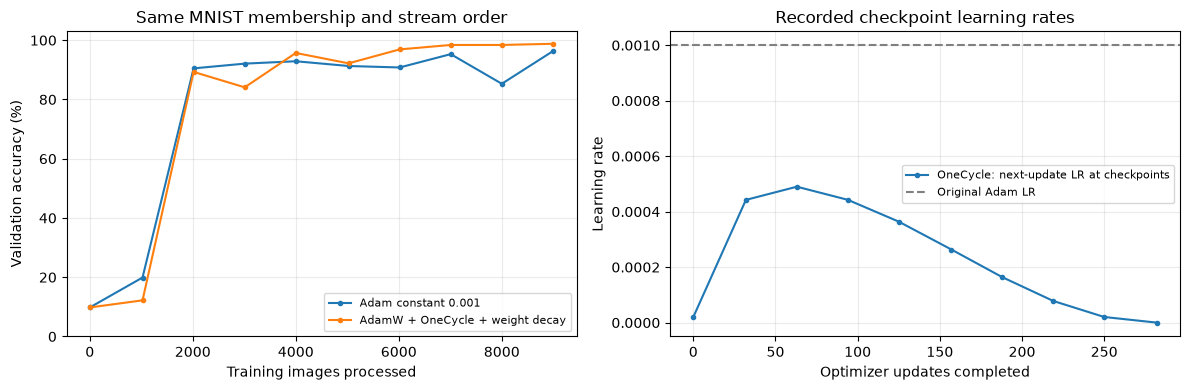

OneCycle optimizer LR changes every update; chart shows only saved checkpoints, not the full schedule.


In [2]:
fig, axes=plt.subplots(1,2,figsize=(12,4))
axes[0].plot(old.examples_processed,old.accuracy*100,marker=".",label="Adam constant 0.001")
axes[0].plot(new.examples_processed,new.accuracy*100,marker=".",label="AdamW + OneCycle + weight decay")
axes[0].set(xlabel="Training images processed",ylabel="Validation accuracy (%)",ylim=(0,103),title="Same MNIST membership and stream order")
axes[0].legend(fontsize=8)
axes[1].plot(new.updates,new.current_learning_rate,marker=".",label="OneCycle: next-update LR at checkpoints")
axes[1].axhline(.001,color="gray",ls="--",label="Original Adam LR")
axes[1].set(xlabel="Optimizer updates completed",ylabel="Learning rate",title="Recorded checkpoint learning rates")
axes[1].legend(fontsize=8)
for ax in axes: ax.grid(alpha=.25)
fig.tight_layout(); plt.show()
print("OneCycle optimizer LR changes every update; chart shows only saved checkpoints, not the full schedule.")

## Reproduce

```powershell
python -m src.train_online --config configs/mnist_nguyen_optimizer.yaml --output data/processed/mnist_nguyen_optimizer_seed42
python -m src.audit_mnist --run data/processed/mnist_nguyen_optimizer_seed42 --output results/mnist_nguyen_optimizer_seed42/audit
```

Use fresh output folders; the completed run remains preserved. Official test images were not evaluated. Checkpoint inference independently reproduced all final metrics without changing model state. The audit JSON/predictions and diagnostic plots are archived alongside the results. Training compute excludes evaluation/loading; wall time includes them during the timed run and excludes initial dataset setup. Hardware and versions are saved in each run.json; runtime differences between separate runs should not be interpreted as an isolated optimizer speed measurement.

Latest pre-run automated regression: **32 passed in 23.84s**. Tests include comparison of all 282 optimizer LR/beta1 values against Nguyen's direct constructor, exactly one schedule step per update, and preservation of original Adam defaults.